# Лабораторная 2. Классическая обработка изображений

**Шереметов Мурат Олегович · Т.МО41 · вариант 22**

В одном ноутбуке выполнены обе части: анализ яркости и фильтрация шума,
затем пороговая сегментация и признаки формы.
[Условие и исходный шаблон](https://github.com/ykvnkm/computer-vision-course/tree/main/labs/lab02).

**Запуск:** в Colab выберите обычную среду CPU и выполните «Среда выполнения → Выполнить всё».
В Kaggle включите Internet. Данные скачиваются автоматически, результаты создаются в `results/`.
В конце формируется `results.zip`. Случайная выборка и шум используют фиксированные seed.
GPU не требуется. Локально запускайте ноутбук из папки `lab02/`.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 22
DATA_SOURCE = None  # Необязательно: папка с локальным архивом variant_22.zip.

import sys
import io
import contextlib
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 1 <= VARIANT <= 22
if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
else:
    ENV, DATA_ROOT = "local", Path("../data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
script_path = DATA_ROOT / "get_data.py"
if not script_path.exists():
    urllib.request.urlretrieve(GET_DATA_URL, script_path)
sys.path.insert(0, str(DATA_ROOT.resolve()))
from get_data import ensure_variant

kwargs = {"dest": DATA_ROOT}
if DATA_SOURCE:
    kwargs["source"] = DATA_SOURCE
# Не сохраняем абсолютные пути локального компьютера в выводе ноутбука.
loader_log = io.StringIO()
with contextlib.redirect_stdout(loader_log):
    loaded_dir = Path(ensure_variant(VARIANT, **kwargs))
print(loader_log.getvalue().replace(str(DATA_ROOT.resolve()), str(DATA_ROOT)))
DATA_DIR = DATA_ROOT / loaded_dir.name
print("среда:", ENV, "| вариант:", VARIANT, "| данные:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

Вариант 22 уже на месте: ../data/variant_22

среда: local | вариант: 22 | данные: ../data/variant_22
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import importlib.util
import subprocess
import platform
import time
import json

packages = {"numpy": "numpy", "pandas": "pandas", "cv2": "opencv-python-headless",
            "matplotlib": "matplotlib", "PIL": "Pillow", "skimage": "scikit-image",
            "pywt": "PyWavelets"}
missing_packages = [package for module, package in packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "--no-cache-dir", "--disable-pip-version-check", *missing_packages])

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import skimage
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity
from IPython.display import display

cv2.setNumThreads(1)
cv2.ocl.setUseOpenCL(False)
plt.rcParams["font.family"] = "DejaVu Sans"
IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
labels = pd.read_csv(DATA_DIR / "labels.csv")
variant_info = json.loads((DATA_DIR / "variant.json").read_text())
assert variant_info["variant"] == VARIANT
assert len(labels) == variant_info["n_images"] and labels["filename"].is_unique
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("Python", platform.python_version(), "| OpenCV", cv2.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| skimage", skimage.__version__)
display(labels.groupby(["breed", "species"]).size().rename("n_images").to_frame())

800 фото, 4 породы: Birman, newfoundland, Siamese, yorkshire_terrier
Python 3.12.10 | OpenCV 4.14.0 | numpy 2.5.4 | pandas 2.3.3 | skimage 0.26.0


,,n_images
breed,species,
Birman,cat,200
Siamese,cat,200
newfoundland,dog,200
yorkshire_terrier,dog,200


### Общие функции

Фото читаются через Pillow и переводятся в RGB. Длинная сторона приводится к 512 px
с сохранением пропорций; маленькие снимки увеличиваются. Это общий масштаб для всех опытов.
Маска trimap изменяет размер только методом ближайшего соседа: 1 = животное, 2 = фон, 3 = граница.
Граница исключается при оценке IoU.

In [3]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()
    plt.close(fig)


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

Birman_1.jpg (512, 384, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Функция `image_stats` реализована ниже. Следующая ячейка она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Яркость и контраст Lab L, оценка шума и дисперсия Лапласиана."""
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return {
        "mean_L": float(L.mean()),
        "std_L": float(L.std()),
        # Float без нормирования: sigma остаётся в единицах шкалы 0..255.
        "noise_sigma": float(estimate_sigma(gray.astype(np.float64), channel_axis=None)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
    }

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,444.54,388.58,123.00,62.18,1.55,650.28
std,84.73,82.05,28.14,13.41,1.36,814.80
min,133.00,150.00,47.51,17.00,0.14,7.60
25%,375.00,333.00,104.05,52.93,0.71,164.25
50%,500.00,375.00,125.44,61.72,1.11,383.47
75%,500.00,500.00,141.11,71.71,1.87,781.02
max,679.00,798.00,217.13,101.35,10.43,5470.87


In [6]:
display(stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean().round(3))
print("Оценка noise_sigma может реагировать и на текстуру шерсти; это не известный уровень добавленного шума.")

,mean_L,std_L,noise_sigma,sharpness
breed,,,,
Birman,123.720,59.365,1.168,399.054
Siamese,122.392,61.663,1.158,408.455
newfoundland,124.352,70.466,2.352,1122.164
yorkshire_terrier,121.521,57.230,1.508,671.463


Оценка noise_sigma может реагировать и на текстуру шерсти; это не известный уровень добавленного шума.


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

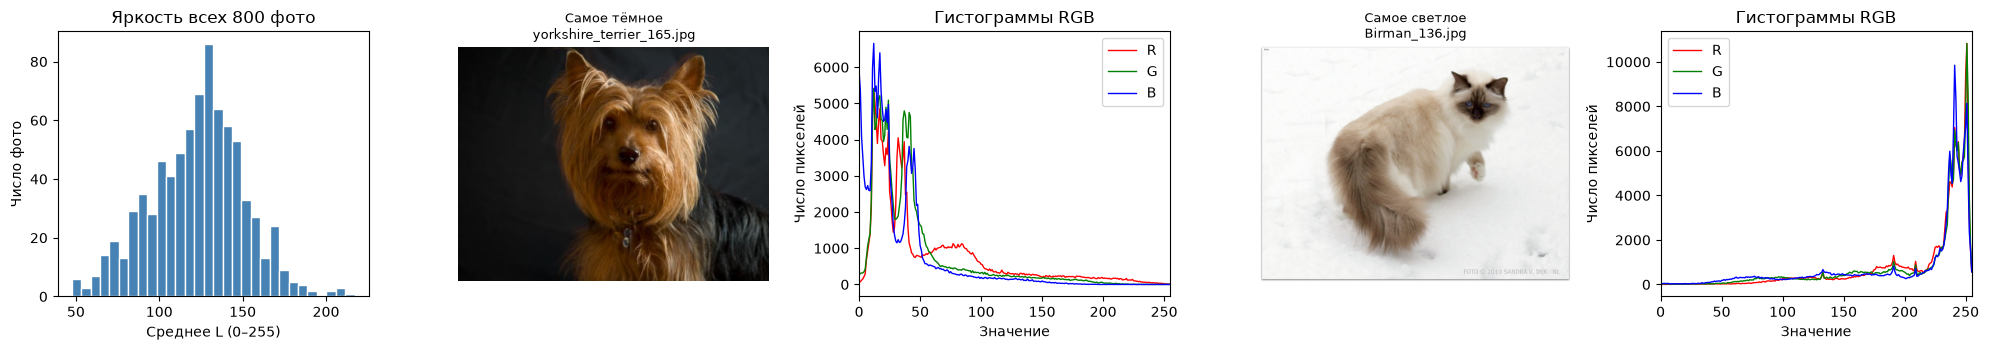

,filename,mean_L,std_L
135,Birman_136.jpg,217.133135,47.086252
764,yorkshire_terrier_165.jpg,47.514628,43.386183


In [7]:
darkest = stats.loc[stats["mean_L"].idxmin(), "filename"]
brightest = stats.loc[stats["mean_L"].idxmax(), "filename"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
axes[0].hist(stats["mean_L"], bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="Яркость всех 800 фото", xlabel="Среднее L (0–255)", ylabel="Число фото")
for start, fn, title in [(1, darkest, "Самое тёмное"), (3, brightest, "Самое светлое")]:
    img = load_rgb(fn)
    axes[start].imshow(img)
    axes[start].set_title(f"{title}\n{fn}", fontsize=9)
    axes[start].axis("off")
    for c, color in enumerate(["red", "green", "blue"]):
        axes[start + 1].plot(np.bincount(img[..., c].ravel(), minlength=256),
                             color=color, label="RGB"[c], linewidth=1)
    axes[start + 1].set(title="Гистограммы RGB", xlabel="Значение", ylabel="Число пикселей", xlim=(0, 255))
    axes[start + 1].legend()
fig.tight_layout()
fig.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()
plt.close(fig)
display(stats.loc[stats["filename"].isin([darkest, brightest]), ["filename", "mean_L", "std_L"]])

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5


def correct(rgb, method):
    """Коррекция освещённости, результат RGB uint8."""
    if method == "eq_rgb":
        return cv2.merge([cv2.equalizeHist(c) for c in cv2.split(rgb)])
    if method in ("eq_L", "clahe_L"):
        L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
        if method == "eq_L":
            L = cv2.equalizeHist(L)
        else:
            L = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(L)
        return cv2.cvtColor(cv2.merge([L, a, b]), cv2.COLOR_LAB2RGB)
    if method == "gamma":
        lut = np.rint(255 * (np.arange(256) / 255.0) ** GAMMA).astype(np.uint8)
        return cv2.LUT(rgb, lut)
    raise ValueError(f"Неизвестный метод: {method}")

,mean_L,std_L,color_shift
method,,,
clahe_L,69.962,58.275,0.292
eq_L,130.130,70.502,1.090
eq_rgb,135.778,71.679,21.810
gamma,104.856,48.829,5.725
original,49.481,47.653,0.000


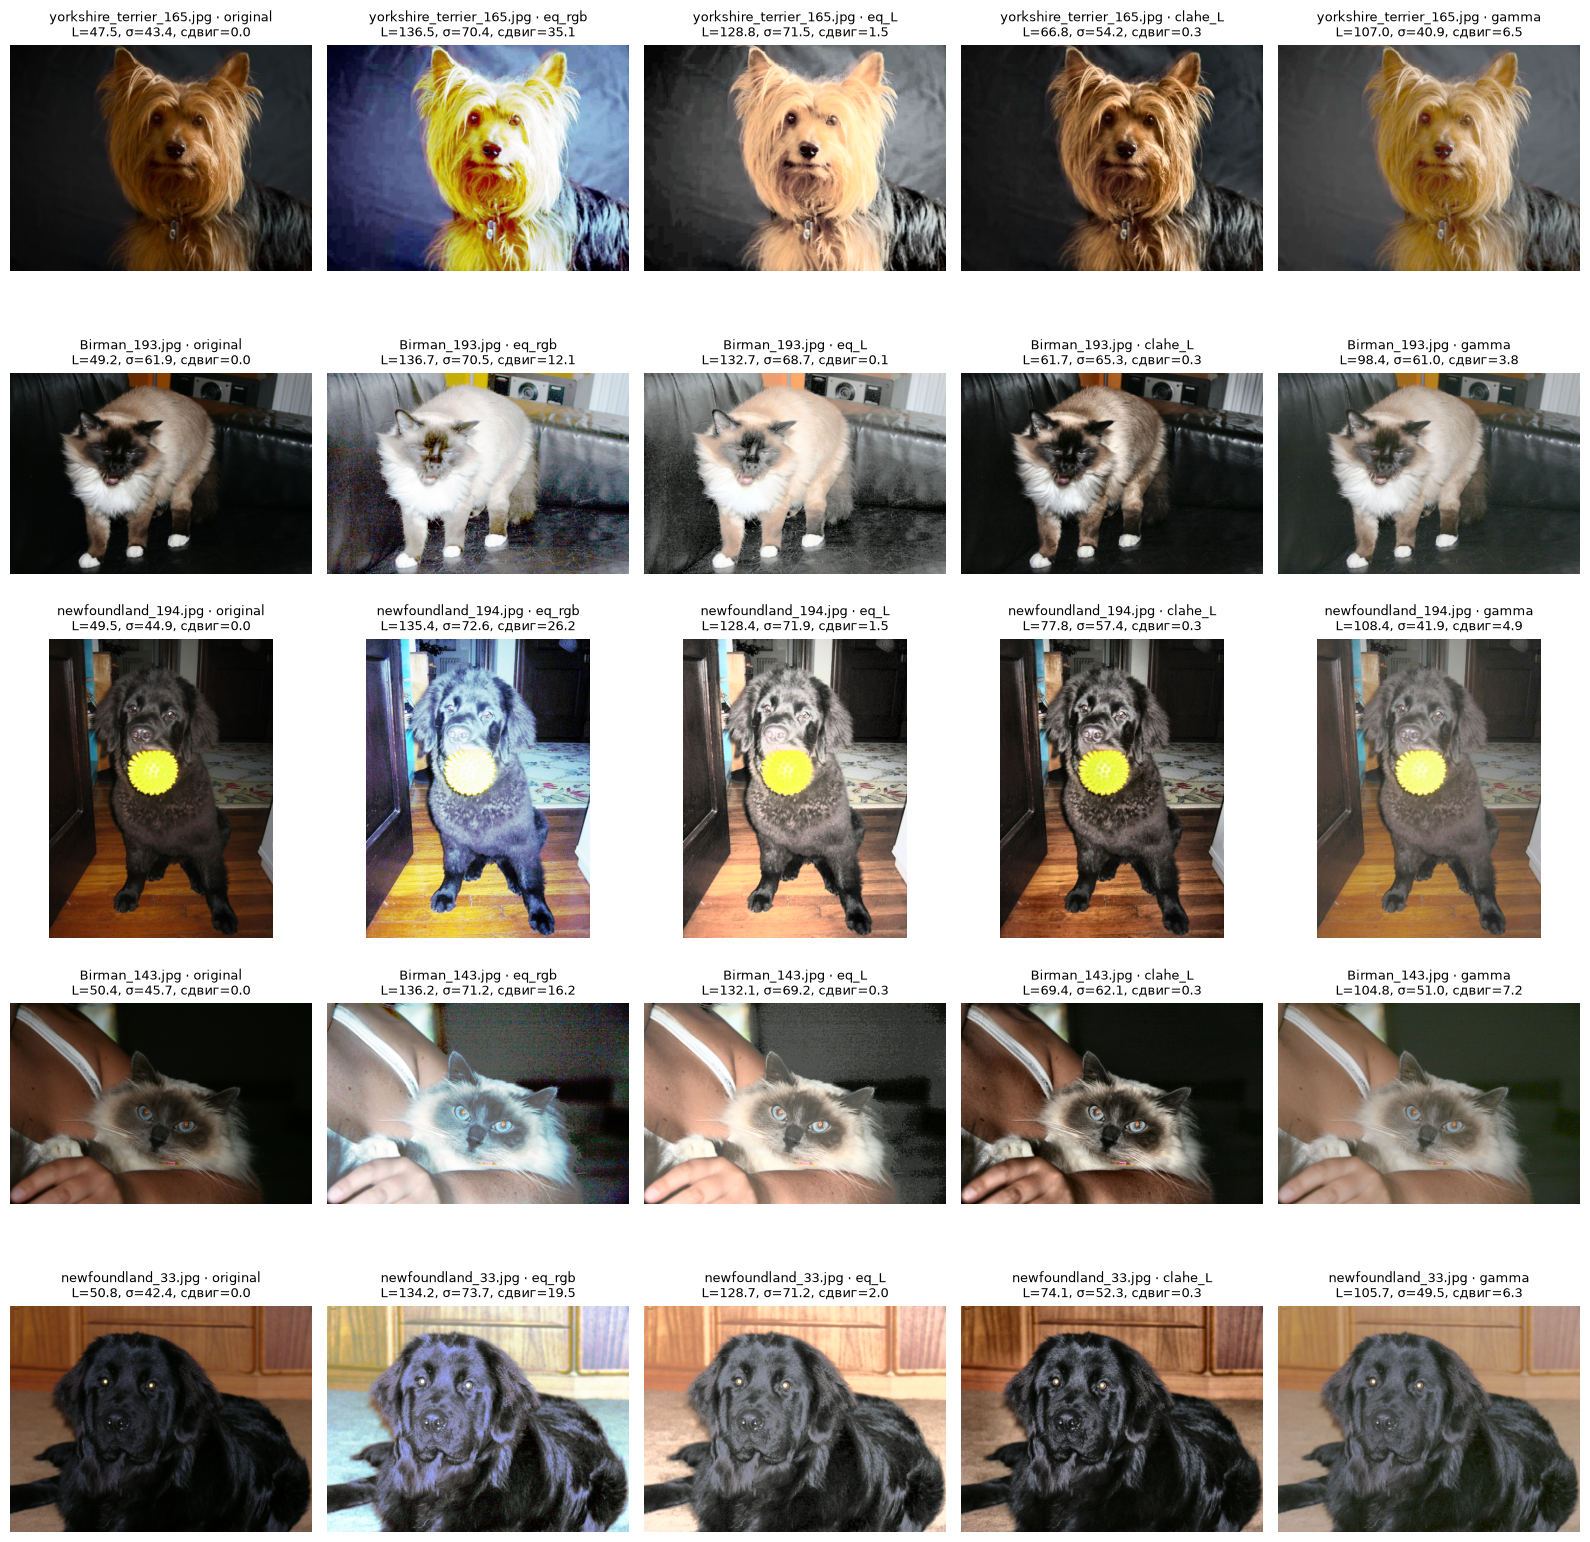

In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]
illum_rows, panels, titles = [], [], []
for fn in stats.nsmallest(5, "mean_L")["filename"]:
    original = load_rgb(fn)
    for method in ["original", *METHODS]:
        out = original if method == "original" else correct(original, method)
        L = cv2.cvtColor(out, cv2.COLOR_RGB2LAB)[..., 0]
        shift = color_shift(original, out)
        illum_rows.append({"filename": fn, "method": method, "mean_L": float(L.mean()),
                           "std_L": float(L.std()), "color_shift": shift})
        panels.append(out)
        titles.append(f"{fn} · {method}\nL={L.mean():.1f}, σ={L.std():.1f}, сдвиг={shift:.1f}")
illum = pd.DataFrame(illum_rows)
illum.to_csv(RESULTS / "illumination.csv", index=False, float_format="%.6f")
display(illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean().round(3))
show_grid(panels, titles, ncols=5, path=RESULTS / "illumination.png", size=3.2)

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [11]:
kernel = np.ones((3, 3), dtype=np.float32) / 9
manual = cv2.filter2D(example, -1, kernel)
builtin = cv2.blur(example, (3, 3))
diff = np.abs(manual.astype(np.int16) - builtin.astype(np.int16))
print("Максимум модуля разницы:", diff.max())
print("Побитовое равенство:", np.array_equal(manual, builtin))
assert diff.max() <= 1  # Допускаем 1 уровень из-за округления разных реализаций.

Максимум модуля разницы: 0
Побитовое равенство: True


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM (максимум 1) (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=sp amount=0.1


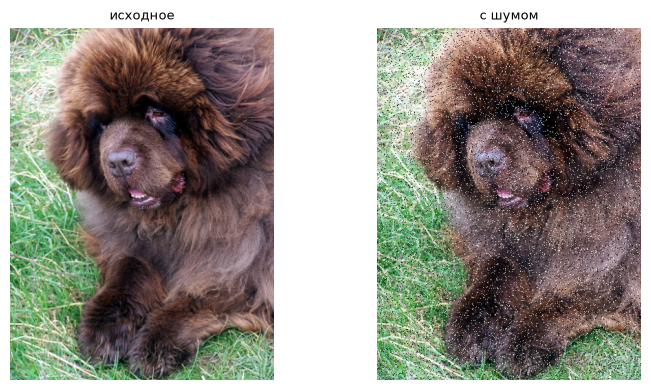

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
FILTERS = {}
for k in (3, 5, 7):
    FILTERS[f"blur{k}"] = lambda img, k=k: cv2.blur(img, (k, k))
    FILTERS[f"gaussian{k}"] = lambda img, k=k: cv2.GaussianBlur(img, (k, k), 0)
    FILTERS[f"median{k}"] = lambda img, k=k: cv2.medianBlur(img, k)
FILTERS["bilateral"] = lambda img: cv2.bilateralFilter(img, 9, 75, 75)

In [15]:
def quality(clean_img, out_img):
    """Сравнение с чистым RGB-кадром в диапазоне 0..255."""
    return {"psnr": float(cv2.PSNR(clean_img, out_img)),
            "ssim": float(structural_similarity(clean_img, out_img, channel_axis=2, data_range=255))}

In [16]:
# none — шумное фото без фильтра. Прогреваем фильтр перед замером.
# Время включает только фильтрацию, без чтения файлов и расчёта метрик.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    f(noisy[0])
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        assert out.shape == c.shape and out.dtype == np.uint8
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv", float_format="%.6f")
display(filt_summary.sort_values("ssim", ascending=False).round(4))

,noise,ms,psnr,ssim
filter,,,,
median3,kind=sp amount=0.1,0.3077,33.9072,0.9306
median5,kind=sp amount=0.1,1.5114,31.2556,0.8606
median7,kind=sp amount=0.1,2.9086,29.4907,0.8081
blur7,kind=sp amount=0.1,0.6824,25.0232,0.6224
gaussian7,kind=sp amount=0.1,0.4778,25.1189,0.5936
blur5,kind=sp amount=0.1,0.3544,24.8375,0.5648
gaussian5,kind=sp amount=0.1,0.2976,24.1337,0.5067
blur3,kind=sp amount=0.1,0.2732,23.0598,0.4352
gaussian3,kind=sp amount=0.1,0.4014,22.4538,0.4119


Кропы из newfoundland_158.jpg ; в подписях средняя SSIM по 30 полным фото.


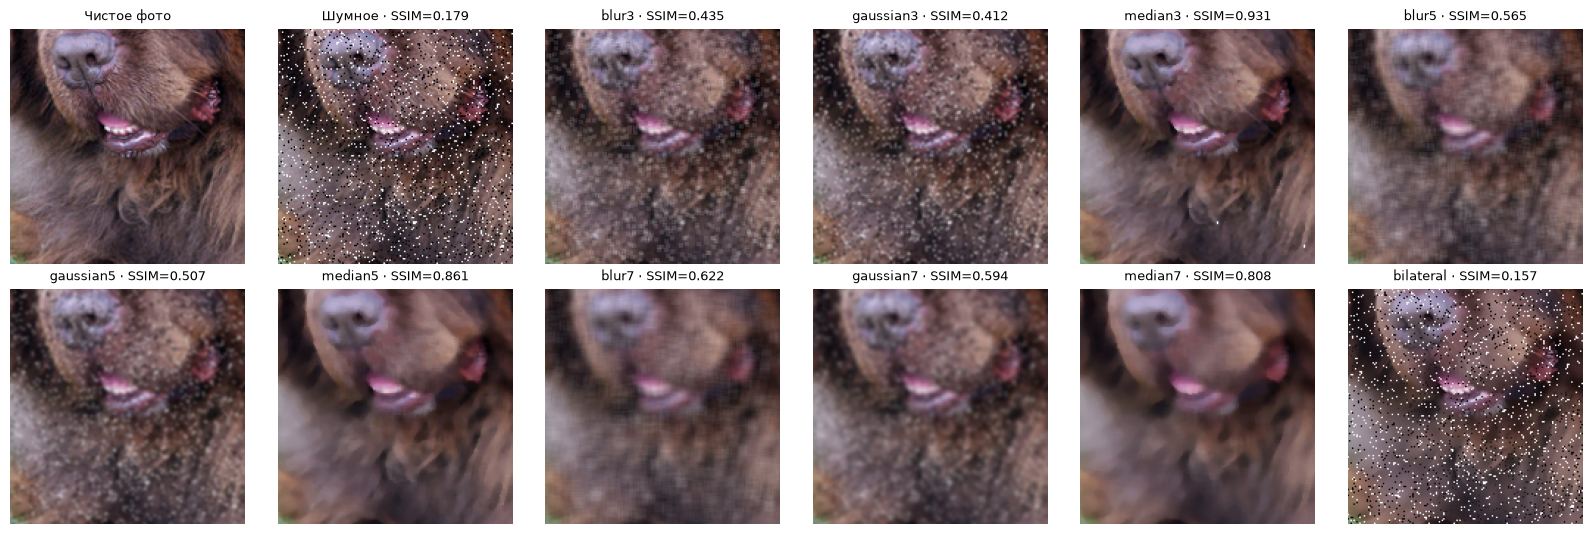

In [17]:
def center_crop(img, side=160):
    h, w = img.shape[:2]
    y, x = max(0, (h - side) // 2), max(0, (w - side) // 2)
    return img[y:y + side, x:x + side]


panels = [center_crop(clean[0]), center_crop(noisy[0])]
titles = ["Чистое фото", f"Шумное · SSIM={filt_summary.loc['none', 'ssim']:.3f}"]
for name, f in FILTERS.items():
    panels.append(center_crop(f(noisy[0])))
    titles.append(f"{name} · SSIM={filt_summary.loc[name, 'ssim']:.3f}")
print("Кропы из", sample["filename"].iloc[0], "; в подписях средняя SSIM по 30 полным фото.")
show_grid(panels, titles, ncols=6, path=RESULTS / "filters.png", size=2.7)

In [18]:
# Приоритет — средняя SSIM; при равенстве смотрим PSNR и время.
ranking = filt_summary.drop(index="none").sort_values(
    ["ssim", "psnr", "ms"], ascending=[False, False, True])
BEST_FILTER = ranking.index[0]
psnr_winner = filt_summary.drop(index="none")["psnr"].idxmax()
print("BEST_FILTER =", BEST_FILTER, "| победитель по PSNR:", psnr_winner)
display(ranking.head(3).round(4))

BEST_FILTER = median3 | победитель по PSNR: median3


,noise,ms,psnr,ssim
filter,,,,
median3,kind=sp amount=0.1,0.3077,33.9072,0.9306
median5,kind=sp amount=0.1,1.5114,31.2556,0.8606
median7,kind=sp amount=0.1,2.9086,29.4907,0.8081


**Почему выбран `median3`.** Медианный фильтр 3×3 победил по обеим метрикам: PSNR 33.91 дБ и SSIM 0.9306; у второго, `median5`, PSNR 31.26 дБ и SSIM 0.8606. Среднее время победителя составило 0.308 мс/кадр против 1.511 мс у `median5`. На кропах он убирает чёрные и белые выбросы и лучше сохраняет мелкую шерсть: медиана устойчива к отдельным экстремальным значениям, а окно 3×3 размывает детали меньше, чем 5×5 и 7×7.

# Часть 2. Выделение животного и признаки формы

Пайплайн: фильтр → канал → Оцу → исправление полярности → морфология → заливка дыр
→ самая большая связная компонента. Trimap используется только для оценки качества
и сравнения общих настроек; функция сегментации получает только само фото.
Из части 1 используется `BEST_FILTER`. Искусственный шум в этой части не добавляется.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Девять панелей показывают исходное фото, trimap, серое изображение, Оцу,
исправление полярности, морфологию, заполнение дыр и выбор компоненты, контур,
адаптивный порог. В этой иллюстрации используем серый канал без предварительного фильтра;
в полной функции ниже фильтрация включается отдельным флагом.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

newfoundland_158.jpg (512, 384, 3) значения trimap: [1 2 3]


Изображение: newfoundland_158.jpg | порог Оцу: 112.0


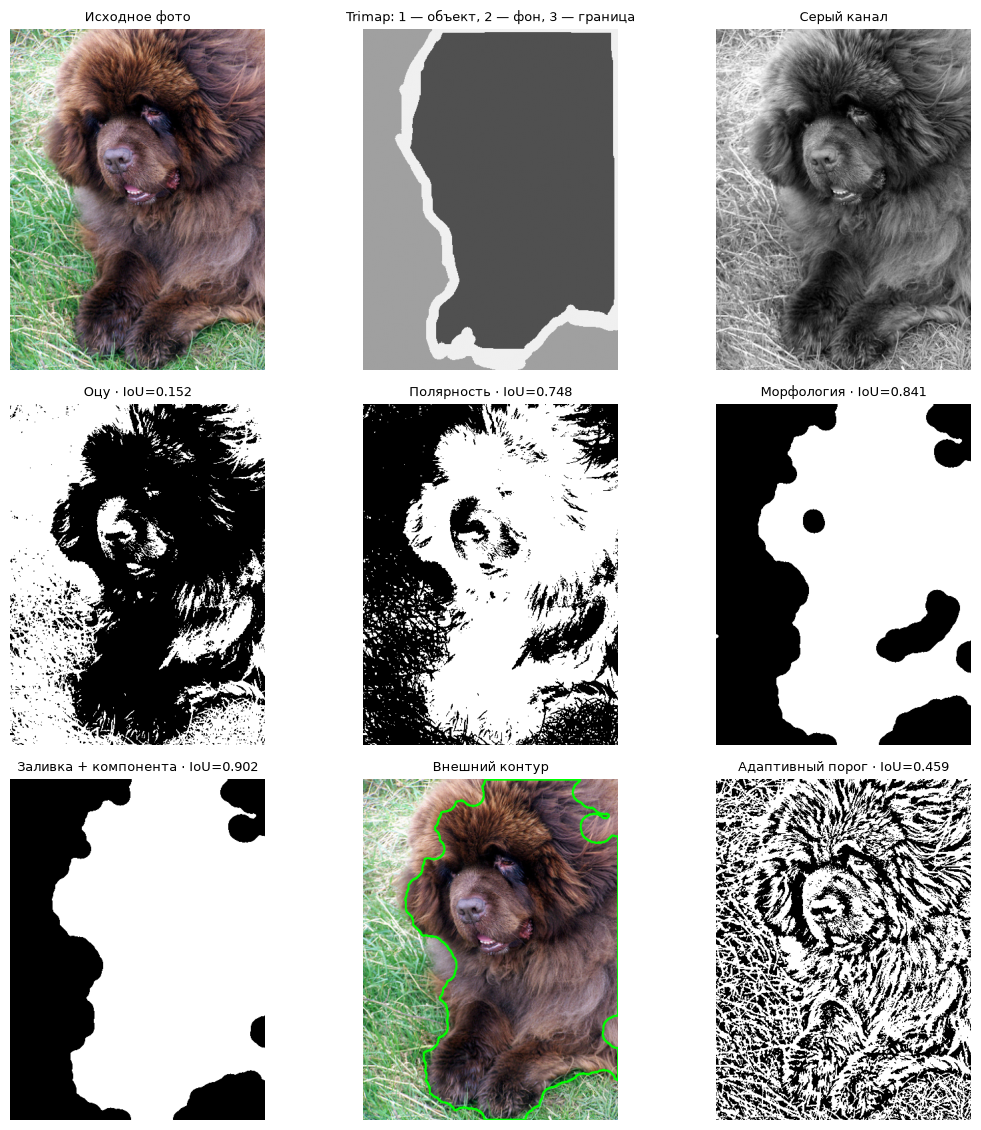

In [21]:
def fix_polarity(mask, border_width=10):
    """Инверсия, если больше половины пикселей рамки стали передним планом."""
    out = (np.asarray(mask) > 0).astype(np.uint8) * 255
    border = np.zeros(out.shape, dtype=bool)
    border[:border_width, :] = border[-border_width:, :] = True
    border[:, :border_width] = border[:, -border_width:] = True
    return cv2.bitwise_not(out) if (out[border] > 0).mean() > 0.5 else out


def morph_cleanup(mask, k_open=7, k_close=31):
    opening = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
    closing = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))
    out = cv2.morphologyEx(mask, cv2.MORPH_OPEN, opening)
    return cv2.morphologyEx(out, cv2.MORPH_CLOSE, closing)


def fill_holes(mask):
    """Нулевая рамка обеспечивает старт floodFill снаружи объекта, даже у края фото."""
    binary = (np.asarray(mask) > 0).astype(np.uint8) * 255
    padded = cv2.copyMakeBorder(binary, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flooded = padded.copy()
    cv2.floodFill(flooded, None, (0, 0), 255)
    holes = cv2.bitwise_not(flooded)[1:-1, 1:-1]
    return cv2.bitwise_or(binary, holes)


def largest_component(mask):
    binary = (np.asarray(mask) > 0).astype(np.uint8)
    count, components, properties, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    if count <= 1:
        return np.zeros_like(binary)
    largest = 1 + np.argmax(properties[1:, cv2.CC_STAT_AREA])
    return (components == largest).astype(np.uint8) * 255


def contour_on_image(rgb, mask):
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return cv2.drawContours(rgb.copy(), contours, -1, (0, 255, 0), 2)


gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
threshold, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
polar = fix_polarity(otsu)
morph_mask = morph_cleanup(polar)
filled = largest_component(fill_holes(morph_mask))
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY, 51, 5)
print("Изображение:", EXAMPLE, "| порог Оцу:", threshold)
panels = [rgb, tri * 80, gray, otsu, polar, morph_mask, filled,
          contour_on_image(rgb, filled), adaptive]
titles = ["Исходное фото", "Trimap: 1 — объект, 2 — фон, 3 — граница", "Серый канал",
          f"Оцу · IoU={iou_ignore(otsu, tri):.3f}",
          f"Полярность · IoU={iou_ignore(polar, tri):.3f}",
          f"Морфология · IoU={iou_ignore(morph_mask, tri):.3f}",
          f"Заливка + компонента · IoU={iou_ignore(filled, tri):.3f}", "Внешний контур",
          f"Адаптивный порог · IoU={iou_ignore(adaptive, tri):.3f}"]
show_grid(panels, titles, ncols=3, path=RESULTS / "pipeline.png", size=3.8)

## 2.2 Функция `segment` и выбор канала

Каждый этап включается отдельным флагом. Сравниваем все шесть каналов из `CHANNELS`
на всех 800 фотографиях и выбираем максимальную среднюю IoU.
Это оценка и подбор настроек на одном учебном наборе, а не результат на независимом тесте.
Размеры ядер фиксированы: открытие 7×7 и закрытие 31×31.

In [22]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    """Маска животного: bool-массив той же высоты и ширины, что и фото."""
    work = FILTERS[BEST_FILTER](rgb) if smooth else rgb
    x = CHANNELS[channel](work)
    _, mask = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if polarity:
        mask = fix_polarity(mask)
    if morph:
        mask = morph_cleanup(mask, k_open, k_close)
    if fill:
        mask = largest_component(fill_holes(mask))
    return mask > 0

In [23]:
def evaluate(configs):
    """Таблица IoU: строка = фото, столбец = конфигурация segment."""
    rows = []
    for i, fn in enumerate(labels["filename"], start=1):
        img = load_rgb(fn)
        truth = load_trimap(fn, img.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(img, **kw), truth)
                                         for name, kw in configs.items()}})
        if i % 200 == 0:
            print(f"Оценено {i}/{len(labels)} фото")
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()})

In [24]:
ch = evaluate({name: dict(channel=name) for name in CHANNELS})
channel_summary = summarize(ch).sort_values("mean_iou", ascending=False)
channel_summary.to_csv(RESULTS / "channels.csv", index_label="channel", float_format="%.6f")
CHANNEL = channel_summary.index[0]
display(channel_summary.round(4))
print("CHANNEL =", CHANNEL)

Оценено 200/800 фото


Оценено 400/800 фото


Оценено 600/800 фото


Оценено 800/800 фото


,mean_iou,median_iou
L,0.4657,0.4244
V,0.4587,0.4283
gray,0.4523,0.4285
S,0.3840,0.3541
b,0.3800,0.3508
a,0.3104,0.2039


CHANNEL = L


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [25]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step", float_format="%.6f")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

Оценено 200/800 фото


Оценено 400/800 фото


Оценено 600/800 фото


Оценено 800/800 фото
канал: L | фильтр: median3


,mean_iou,median_iou
1 только Оцу,0.231397,0.197473
2 + фильтр из части 1,0.231513,0.199186
3 + полярность,0.420397,0.382122
4 + морфология,0.442180,0.404123
5 + заливка и компонента,0.465694,0.424405


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

`shape_features` обрабатывает и пустые маски. Следующая ячейка она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [26]:
def shape_features(mask):
    """Признаки самого большого внешнего контура; NaN для неопределённых отношений."""
    binary = (np.asarray(mask) > 0).astype(np.uint8)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return {"area_frac": 0.0, "perimeter": 0.0, "x": 0, "y": 0, "w": 0, "h": 0,
                "elongation": np.nan, "circularity": np.nan, "solidity": np.nan}
    c = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(c))
    perimeter = float(cv2.arcLength(c, True))
    x, y, w, h = cv2.boundingRect(c)
    short, long = sorted(cv2.minAreaRect(c)[1])
    hull_area = float(cv2.contourArea(cv2.convexHull(c)))
    return {"area_frac": area / binary.size, "perimeter": perimeter,
            "x": x, "y": y, "w": w, "h": h,
            "elongation": long / short if short > 0 else np.nan,
            "circularity": 4 * np.pi * area / perimeter**2 if perimeter > 0 else np.nan,
            "solidity": area / hull_area if hull_area > 0 else np.nan}

In [27]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.6f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,Birman_1.jpg,Birman,cat,0.177839,0.203753,2016.060087,63,85,321,427,1.669645,0.123854,0.468598
1,Birman_2.jpg,Birman,cat,0.346945,0.719452,3219.523071,0,0,512,342,1.498534,0.152730,0.754806
2,Birman_3.jpg,Birman,cat,0.855310,0.501767,2189.883461,0,0,449,384,1.169713,0.258507,0.692899
3,Birman_4.jpg,Birman,cat,0.428600,0.366206,2557.169820,0,77,333,435,1.247730,0.138362,0.565408
4,Birman_5.jpg,Birman,cat,0.514234,0.825358,2086.312832,0,0,512,343,1.494152,0.418463,0.854332


In [28]:
features = ["iou", "area_frac", "elongation", "circularity", "solidity"]
print("Средние по породам:")
display(masks.groupby("breed")[features].mean().round(4))
print("Средние по виду животного:")
display(masks.groupby("species")[features].mean().round(4))
print("Пустых масок:", int((masks["w"] == 0).sum()))
print("Признаки описывают предсказанную маску; при ошибке сегментации они могут характеризовать фон.")

Средние по породам:


,iou,area_frac,elongation,circularity,solidity
breed,,,,,
Birman,0.4230,0.3878,1.5075,0.3169,0.7199
Siamese,0.3949,0.3817,1.4439,0.2915,0.6946
newfoundland,0.6659,0.4541,1.4716,0.3733,0.7638
yorkshire_terrier,0.3789,0.4384,1.4491,0.2635,0.7049


Средние по виду животного:


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.4090,0.3848,1.4757,0.3042,0.7073
dog,0.5224,0.4463,1.4603,0.3184,0.7343


Пустых масок: 0
Признаки описывают предсказанную маску; при ошибке сегментации они могут характеризовать фон.


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

Зелёным показана предсказанная маска. IoU в подписях округлена до трёх знаков; граница trimap = 3 исключена из оценки, поэтому IoU = 1 не гарантирует точного совпадения контуров.

Зелёным показана предсказанная маска; верхний ряд — лучшие, нижний — худшие.


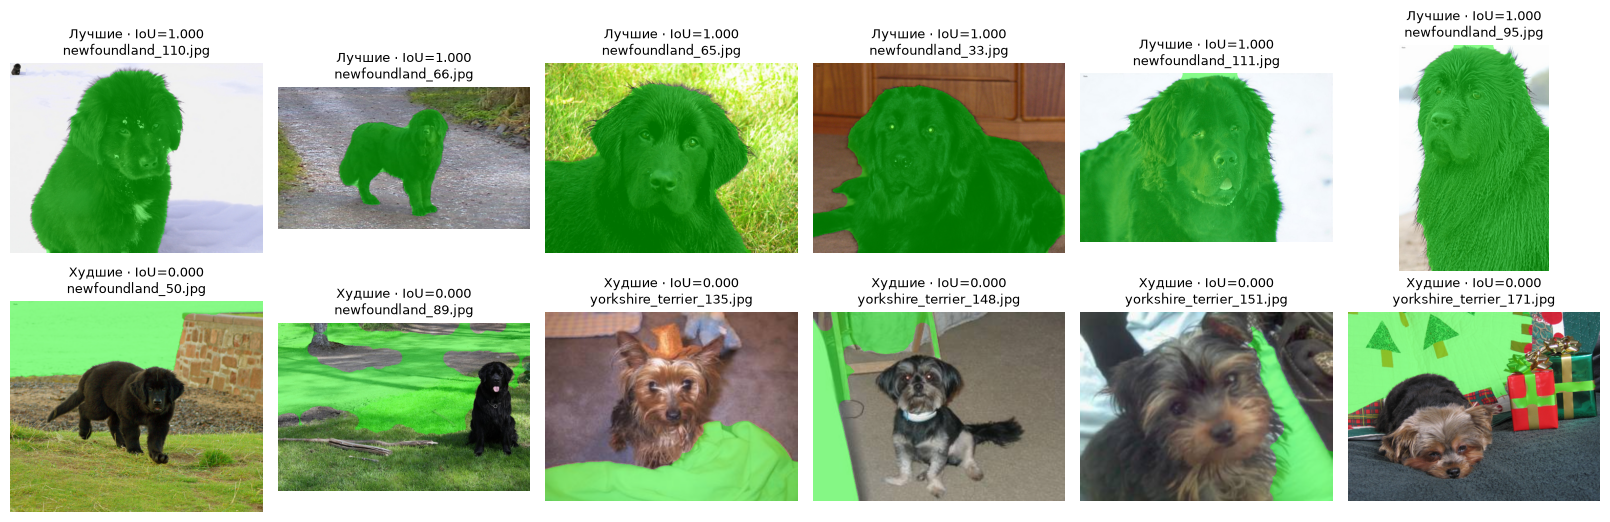

,group,filename,iou
309,best,newfoundland_110.jpg,1.000000
265,best,newfoundland_66.jpg,1.000000
264,best,newfoundland_65.jpg,0.999970
232,best,newfoundland_33.jpg,0.999953
310,best,newfoundland_111.jpg,0.999928
294,best,newfoundland_95.jpg,0.999699
249,worst,newfoundland_50.jpg,0.000000
288,worst,newfoundland_89.jpg,0.000000
734,worst,yorkshire_terrier_135.jpg,0.000000
747,worst,yorkshire_terrier_148.jpg,0.000000


In [29]:
ranked = masks.dropna(subset=["iou"]).sort_values(["iou", "filename"], ascending=[False, True])
best = ranked.head(6)
worst = ranked.tail(6).sort_values(["iou", "filename"])
panels, titles = [], []
for group_name, group in [("Лучшие", best), ("Худшие", worst)]:
    for row in group.itertuples():
        img = load_rgb(row.filename)
        mask = segment(img, **FINAL)
        panels.append(overlay(img, mask))
        titles.append(f"{group_name} · IoU={row.iou:.3f}\n{row.filename}")
print("Зелёным показана предсказанная маска; верхний ряд — лучшие, нижний — худшие.")
show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.7)
display(pd.concat([best.assign(group="best"), worst.assign(group="worst")])[["group", "filename", "iou"]])

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [30]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")
expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
assert not missing, f"Отсутствуют файлы: {missing}"
assert len(stats) == len(masks) == len(labels)
assert masks["filename"].is_unique and set(masks["filename"]) == set(labels["filename"])
assert masks["iou"].between(0, 1).all()
assert np.isclose(masks["iou"].mean(), abl_summary.iloc[-1]["mean_iou"])
print("не хватает: ничего, все 9 файлов на месте")
print("Дополнительно: illumination.csv и channels.csv — числа для выводов.")
print("Строк в part1_stats.csv и masks.csv:", len(stats), len(masks))

вариант 22 | шум kind=sp amount=0.1 | BEST_FILTER = median3 | CHANNEL = L
не хватает: ничего, все 9 файлов на месте
Дополнительно: illumination.csv и channels.csv — числа для выводов.
Строк в part1_stats.csv и masks.csv: 800 800


In [31]:
import shutil
archive = shutil.make_archive("results", "zip", RESULTS)
print("Архив: results.zip. Распакуйте его содержимое в lab02/results/ перед загрузкой на GitHub.")
if ENV == "colab":
    from google.colab import files
    files.download(archive)

Архив: results.zip. Распакуйте его содержимое в lab02/results/ перед загрузкой на GitHub.


## Выводы по выполненной работе

1. **Фильтрация.** `median3` дал PSNR **33.91 дБ** и SSIM **0.9306**, а шумное фото без фильтра — 14.86 дБ и 0.1792. Победители по PSNR и SSIM совпали; отрыв от `median5` составляет 2.65 дБ и 0.0700 SSIM. Медиана устраняет одиночные выбросы «соли и перца», а небольшое окно сохраняет фактуру шерсти лучше крупных окон. Источник: [filters.csv](results/filters.csv).

2. **Освещённость и цвет.** На пяти самых тёмных фото независимое выравнивание RGB дало средний сдвиг цвета **21.81**, выравнивание L — 1.09, CLAHE по L — **0.29**. CLAHE повысил среднее L с 49.48 до 69.96. Изменение каждого канала RGB по своей функции нарушает отношения между каналами, что заметно по неестественным оттенкам; обработка только L сохраняет их значительно лучше. Источник: [illumination.csv](results/illumination.csv), средние по пяти фото.

3. **Выбор канала.** Лучшим оказался **L: средняя IoU 0.4657**. У V она равна 0.4587, у серого — 0.4523, у a — 0.3104. В этом наборе разделение по светлоте в среднем оказалось полезнее разделения по цветовому каналу a; разница L и V невелика. Канал выбран на тех же 800 фото, поэтому это результат на учебном наборе, а не оценка обобщения на новых данных. Источник: [channels.csv](results/channels.csv).

4. **Вклад этапов.** Основной прирост дала проверка полярности: средняя IoU выросла с 0.2315 до **0.4204** (на 0.1889). Один фильтр изменил IoU лишь на 0.000116, а весь алгоритм — с 0.2314 до 0.4657. Оцу выбирает порог, но сам не определяет, какой класс является животным; инверсия часто исправляет выбор светлого фона вместо тёмной шерсти. В этой части искусственный шум не добавлялся, поэтому эффект фильтра невелик. Источник: [ablation.csv](results/ablation.csv).

5. **Ошибки сегментации.** У **14 изображений IoU равна 0**; в шести худших примерах на рисунке зелёная маска попадает на фон. Например, `newfoundland_50.jpg` и `newfoundland_89.jpg` имеют IoU 0: алгоритм выбирает светлую область вокруг тёмной собаки. Предположение о фоне по краям и выбор самой большой компоненты не гарантируют, что будет выделено именно животное. Источник: [masks.csv](results/masks.csv) и [best_worst.png](results/best_worst.png).

6. **Форма предсказанных масок.** Средняя вытянутость у кошек составляет **1.476**, у собак — **1.460**; средняя solidity — 0.707 и 0.734. Разница по вытянутости мала. Эти признаки нельзя напрямую считать свойствами пород: при ошибке сегментации они описывают кусок фона, а закрытие и заливка меняют форму маски. Источник: [masks.csv](results/masks.csv), группировка по species.